***Credit Scoring Model Using Machine Learning***

**Project Objective**

The objective of this project is to predict whether a credit card client is likely to default on payment using machine learning classification algorithms.

**Dataset**

The project uses the UCI Default of Credit Card Clients dataset, which contains client demographic information, credit limits, repayment status, bill amounts, and previous payment amounts.

**Models Used**

- Logistic Regression
- Random Forest Classifier
- Tuned Random Forest Classifier

**Evaluation Metrics**

- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC Score

IMPORT LIBRARIES




In [28]:
# Credit Scoring Model
# Project: CodeAlpha Machine Learning Internship

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully!")
print("Credit Scoring Model - Project Started")

Libraries imported successfully!
Credit Scoring Model - Project Started


PIP INSTALLATION

In [29]:
!pip install ucimlrepo

LOAD DATASET

In [30]:
from ucimlrepo import fetch_ucirepo
import pandas as pd

# Fetch the official UCI dataset
credit_data = fetch_ucirepo(id=350)

# Separate input features and target
X = credit_data.data.features
y = credit_data.data.targets

# Combine them into one DataFrame
df = pd.concat([X, y], axis=1)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

Dataset loaded successfully!
Dataset shape: (30000, 24)

First 5 rows:


,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,...,X15,X16,X17,X18,X19,X20,X21,X22,X23,Y
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [31]:
print(df.columns.tolist())

['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'X9', 'X10', 'X11', 'X12', 'X13', 'X14', 'X15', 'X16', 'X17', 'X18', 'X19', 'X20', 'X21', 'X22', 'X23', 'Y']


In [32]:
# Check all column names
print("Column names:")
print(df.columns.tolist())

# Check dataset information
print("\nDataset information:")
df.info()

# Check missing values
print("\nMissing values in each column:")
print(df.isnull().sum())

# Check target column distribution
print("\nTarget distribution:")
print(df["Y"].value_counts())

Column names:
['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'X9', 'X10', 'X11', 'X12', 'X13', 'X14', 'X15', 'X16', 'X17', 'X18', 'X19', 'X20', 'X21', 'X22', 'X23', 'Y']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 24 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   X1      30000 non-null  int64
 1   X2      30000 non-null  int64
 2   X3      30000 non-null  int64
 3   X4      30000 non-null  int64
 4   X5      30000 non-null  int64
 5   X6      30000 non-null  int64
 6   X7      30000 non-null  int64
 7   X8      30000 non-null  int64
 8   X9      30000 non-null  int64
 9   X10     30000 non-null  int64
 10  X11     30000 non-null  int64
 11  X12     30000 non-null  int64
 12  X13     30000 non-null  int64
 13  X14     30000 non-null  int64
 14  X15     30000 non-null  int64
 15  X16     30000 non-null  int64
 16  X17     30000 non-null  int64
 17  X18     30000 non-null  int

DATA CLEANING

In [33]:
column_names = {
    "X1": "LIMIT_BAL",
    "X2": "SEX",
    "X3": "EDUCATION",
    "X4": "MARRIAGE",
    "X5": "AGE",
    "X6": "PAY_0",
    "X7": "PAY_2",
    "X8": "PAY_3",
    "X9": "PAY_4",
    "X10": "PAY_5",
    "X11": "PAY_6",
    "X12": "BILL_AMT1",
    "X13": "BILL_AMT2",
    "X14": "BILL_AMT3",
    "X15": "BILL_AMT4",
    "X16": "BILL_AMT5",
    "X17": "BILL_AMT6",
    "X18": "PAY_AMT1",
    "X19": "PAY_AMT2",
    "X20": "PAY_AMT3",
    "X21": "PAY_AMT4",
    "X22": "PAY_AMT5",
    "X23": "PAY_AMT6",
    "Y": "DEFAULT"
}

df = df.rename(columns=column_names)

print(df.columns.tolist())

['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'DEFAULT']


In [34]:
# Basic statistical analysis

print("Dataset shape:")
print(df.shape)

print("\nStatistical summary:")
display(df[["LIMIT_BAL", "AGE", "DEFAULT"]].describe())

print("\nDefault rate:")
print(round(df["DEFAULT"].mean() * 100, 2), "%")

print("\nAverage credit limit by default status:")
display(
    df.groupby("DEFAULT")["LIMIT_BAL"].mean().round(2)
)

print("\nAverage age by default status:")
display(
    df.groupby("DEFAULT")["AGE"].mean().round(2)
)

Dataset shape:
(30000, 24)

Statistical summary:


,LIMIT_BAL,AGE,DEFAULT
count,30000.000000,30000.000000,30000.000000
mean,167484.322667,35.485500,0.221200
std,129747.661567,9.217904,0.415062
min,10000.000000,21.000000,0.000000
25%,50000.000000,28.000000,0.000000
50%,140000.000000,34.000000,0.000000
75%,240000.000000,41.000000,0.000000
max,1000000.000000,79.000000,1.000000



Default rate:
22.12 %

Average credit limit by default status:


,LIMIT_BAL
DEFAULT,
0,178099.73
1,130109.66



Average age by default status:


,AGE
DEFAULT,
0,35.42
1,35.73


EXPLORATORY DATA ANALYSIS

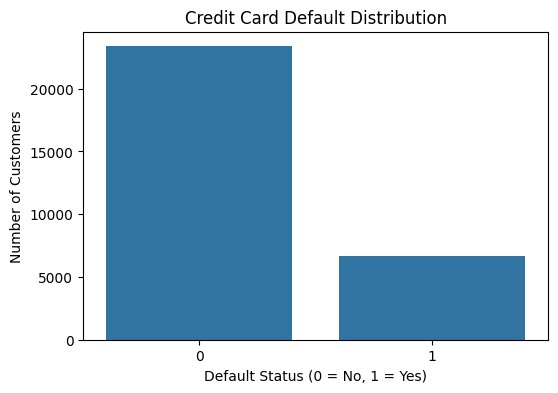

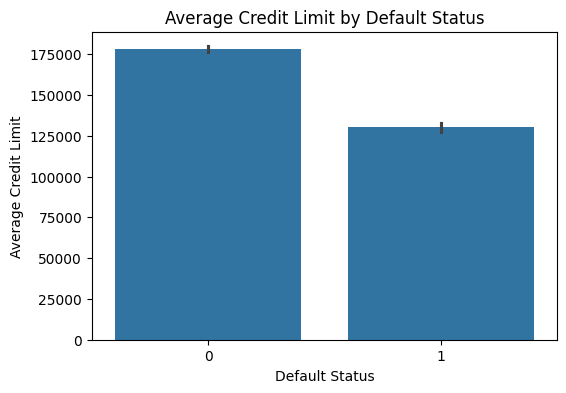

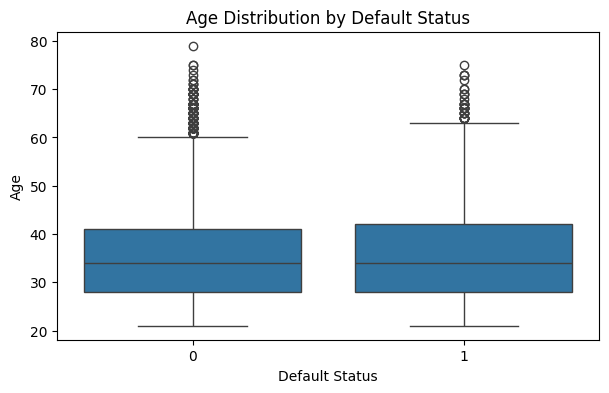

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Target distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="DEFAULT")
plt.title("Credit Card Default Distribution")
plt.xlabel("Default Status (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")
plt.show()

# 2. Average credit limit by default status
plt.figure(figsize=(6, 4))
sns.barplot(data=df, x="DEFAULT", y="LIMIT_BAL")
plt.title("Average Credit Limit by Default Status")
plt.xlabel("Default Status")
plt.ylabel("Average Credit Limit")
plt.show()

# 3. Age distribution by default status
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="DEFAULT", y="AGE")
plt.title("Age Distribution by Default Status")
plt.xlabel("Default Status")
plt.ylabel("Age")
plt.show()

In [36]:
import pandas as pd
import numpy as np

# Check dataset shape
print("Dataset shape:", df.shape)

# Check missing values
print("\nMissing values:")
print(df.isnull().sum().sum())

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Check target distribution
print("\nTarget distribution:")
print(df["DEFAULT"].value_counts())

# Check data types
print("\nData types:")
print(df.dtypes)

Dataset shape: (30000, 24)

Missing values:
0

Duplicate rows: 35

Target distribution:
DEFAULT
0    23364
1     6636
Name: count, dtype: int64

Data types:
LIMIT_BAL    int64
SEX          int64
EDUCATION    int64
MARRIAGE     int64
AGE          int64
PAY_0        int64
PAY_2        int64
PAY_3        int64
PAY_4        int64
PAY_5        int64
PAY_6        int64
BILL_AMT1    int64
BILL_AMT2    int64
BILL_AMT3    int64
BILL_AMT4    int64
BILL_AMT5    int64
BILL_AMT6    int64
PAY_AMT1     int64
PAY_AMT2     int64
PAY_AMT3     int64
PAY_AMT4     int64
PAY_AMT5     int64
PAY_AMT6     int64
DEFAULT      int64
dtype: object


In [37]:
# Remove duplicate rows

print("Rows before removing duplicates:", len(df))

df = df.drop_duplicates().copy()

print("Rows after removing duplicates:", len(df))
print("Remaining duplicate rows:", df.duplicated().sum())

Rows before removing duplicates: 30000
Rows after removing duplicates: 29965
Remaining duplicate rows: 0


TRAIN-TEST SPLIT

In [38]:
from sklearn.model_selection import train_test_split

# Input features and target
X = df.drop("DEFAULT", axis=1)
y = df["DEFAULT"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining data:", X_train.shape)
print("Testing data:", X_test.shape)

Features shape: (29965, 23)
Target shape: (29965,)

Training data: (23972, 23)
Testing data: (5993, 23)


LOGISTIC REGRESSION

In [39]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [40]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("ROC-AUC Score:", roc_auc_score(y_test, y_proba))

Accuracy: 0.6864675454697147

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.70      0.78      4667
           1       0.38      0.63      0.47      1326

    accuracy                           0.69      5993
   macro avg       0.62      0.67      0.62      5993
weighted avg       0.76      0.69      0.71      5993

Confusion Matrix:
[[3279 1388]
 [ 491  835]]
ROC-AUC Score: 0.7161577986834167


RANDOM FOREST

In [41]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    min_samples_split=10,
    min_samples_leaf=4,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

print("Logistic Regression Accuracy:",
      accuracy_score(y_test, y_pred))

print("Random Forest Accuracy:",
      accuracy_score(y_test, rf_pred))

Logistic Regression Accuracy: 0.6864675454697147
Random Forest Accuracy: 0.7877523777740697


In [42]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score
)

rf_proba = rf_model.predict_proba(X_test)[:, 1]

print("Classification Report:")
print(classification_report(y_test, rf_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

print("ROC-AUC Score:",
      roc_auc_score(y_test, rf_proba))

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.86      0.86      4667
           1       0.52      0.54      0.53      1326

    accuracy                           0.79      5993
   macro avg       0.69      0.70      0.70      5993
weighted avg       0.79      0.79      0.79      5993

Confusion Matrix:
[[3999  668]
 [ 604  722]]
ROC-AUC Score: 0.7707552240127644


HYPERPARAMETER TUNING

In [43]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

rf = RandomForestClassifier(
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [8, 12, 16, None],
    "min_samples_split": [5, 10],
    "min_samples_leaf": [2, 4]
}

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("Best Validation ROC-AUC:")
print(grid_search.best_score_)

Fitting 3 folds for each of 32 candidates, totalling 96 fits
Best Parameters:
{'max_depth': 12, 'min_samples_leaf': 4, 'min_samples_split': 10, 'n_estimators': 200}
Best Validation ROC-AUC:
0.7821027641328319


In [44]:
best_model = grid_search.best_estimator_

best_pred = best_model.predict(X_test)
best_proba = best_model.predict_proba(X_test)[:, 1]

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    roc_auc_score
)

print("Tuned Model Accuracy:",
      accuracy_score(y_test, best_pred))

print("\nClassification Report:")
print(classification_report(y_test, best_pred))

print("Tuned Model Test ROC-AUC:",
      roc_auc_score(y_test, best_proba))

Tuned Model Accuracy: 0.7877523777740697

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.86      0.86      4667
           1       0.52      0.54      0.53      1326

    accuracy                           0.79      5993
   macro avg       0.69      0.70      0.70      5993
weighted avg       0.79      0.79      0.79      5993

Tuned Model Test ROC-AUC: 0.7707552240127644


MODEL COMPARISON

In [45]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import pandas as pd

models = {
    "Logistic Regression": (y_pred, model.predict_proba(X_test)[:, 1]),
    "Random Forest": (rf_pred, rf_proba),
    "Tuned Random Forest": (best_pred, best_proba)
}

results = []

for name, (pred, proba) in models.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Default Precision": precision_score(
            y_test, pred, zero_division=0
        ),
        "Default Recall": recall_score(
            y_test, pred, zero_division=0
        ),
        "Default F1": f1_score(
            y_test, pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, proba)
    })

comparison = pd.DataFrame(results)
print(comparison.round(4).to_string(index=False))

              Model  Accuracy  Default Precision  Default Recall  Default F1  ROC-AUC
Logistic Regression    0.6865             0.3756          0.6297      0.4706   0.7162
      Random Forest    0.7878             0.5194          0.5445      0.5317   0.7708
Tuned Random Forest    0.7878             0.5194          0.5445      0.5317   0.7708


FEATURE IMPORTANCE

Top 10 Important Features:
PAY_0        0.219414
PAY_2        0.082277
PAY_4        0.051197
LIMIT_BAL    0.048346
PAY_AMT1     0.047050
PAY_3        0.046221
BILL_AMT1    0.045535
PAY_AMT2     0.045121
BILL_AMT2    0.037554
PAY_AMT3     0.037519
dtype: float64


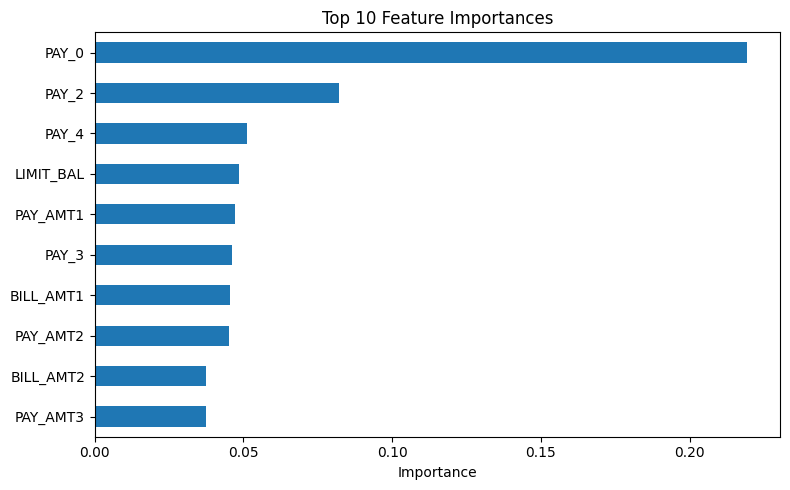

In [46]:
import pandas as pd
import matplotlib.pyplot as plt

best_model = grid_search.best_estimator_

importance = pd.Series(
    best_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print("Top 10 Important Features:")
print(importance.head(10))

importance.head(10).sort_values().plot(
    kind="barh",
    figsize=(8, 5)
)

plt.title("Top 10 Feature Importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

***Conclusion***


In this project, Logistic Regression and Random Forest classifiers were used to predict credit card default.

The Random Forest model achieved approximately 78.78% test accuracy and a ROC-AUC score of 0.7708, outperforming the Logistic Regression model on these metrics. Hyperparameter tuning did not produce a measurable improvement over the baseline Random Forest model.

Feature importance was also analyzed to identify influential predictors. The model is an educational prototype and would require further validation and fairness checks before any real-world credit decisions.